# Day 17 — Drought Impact Analyzer: Corn Belt, 2000–2025

**Question:** how much does drought severity move with US maize yield — across years nationally, and across counties in Iowa and Illinois — and can a precipitation anomaly explain the same signal more simply?

**Sources:** U.S. Drought Monitor REST API (weekly DSCI by state, % area in D0–D4 by county); maize yield: FAO via Our World in Data; weather: Open-Meteo ERA5 archive. DSCI = 1×D0 + 2×D1 + 3×D2 + 4×D3 + 5×D4 on exclusive shares (= D0+D1+D2+D3+D4 on the API's cumulative columns), range 0–500.

**Limits (see README):** national yield vs a 2-state drought/weather proxy; no county yields (USDA Quick Stats needs a key); association, not causation; n = 26 annual rows.

In [1]:
from pathlib import Path
import sys

def _find_root(marker="data/processed/annual_drought_yield.csv"):
    here = Path().resolve()
    for parent in [here, *here.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"could not find {marker} above {here}")

ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
print("root:", ROOT)

root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-17-drought-impact-analyzer


## 1. The annual dataset — 26 years of drought, rain and yield

Growing season = April–September. `gs_dsci_mean` is the Iowa+Illinois average of the weekly DSCI over growing-season weeks; `yield_resid_t_per_ha` is the yield after removing the linear year (technology) trend.

In [2]:
import pandas as pd

annual = pd.read_csv(ROOT / "data/processed/annual_drought_yield.csv")
print(annual.shape)
annual[["year", "yield_t_per_ha", "yield_resid_t_per_ha", "gs_dsci_mean", "gs_precip_anomaly_mm"]].round(3)

(26, 14)


,year,yield_t_per_ha,yield_resid_t_per_ha,gs_dsci_mean,gs_precip_anomaly_mm
0,2000,8.592,0.020,115.788,-46.265
1,2001,8.674,-0.015,28.923,49.235
2,2002,8.115,-0.689,32.385,-9.865
3,2003,8.925,0.004,85.722,-12.315
4,2004,10.061,1.024,5.673,8.085
5,2005,9.283,0.130,108.904,-125.365
6,2006,9.358,0.089,62.250,-101.065
7,2007,9.458,0.074,32.654,-69.815
8,2008,9.621,0.121,2.426,101.885
9,2009,10.318,0.702,2.731,144.185


## 2. The trend — 2012 stands alone

2012 is the worst drought year in the series by a wide margin (growing-season mean DSCI 200.4; Iowa 204.2, Illinois 196.6). The next-worst year, 2023, is at 148.1. Yield in 2012 was 7.73 t/ha — the lowest in the 26 years — 2.24 t/ha below the trend line.

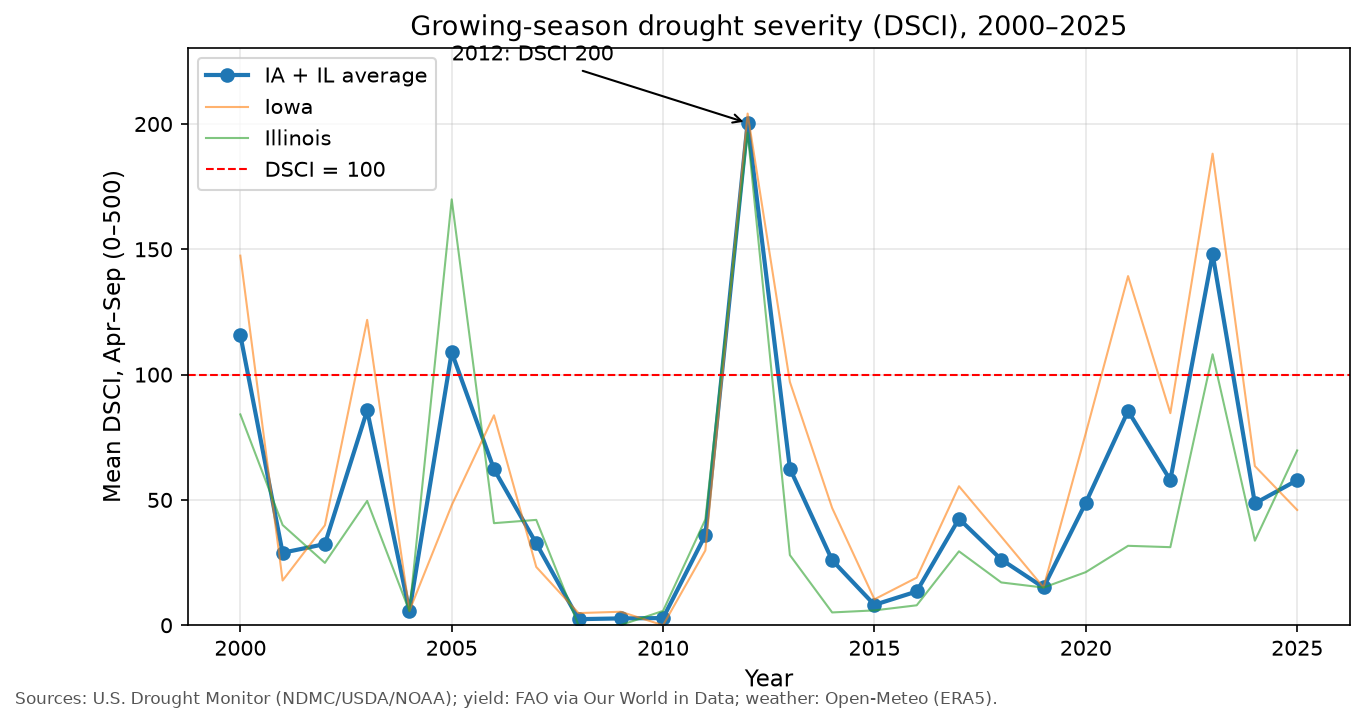

In [3]:
from IPython.display import Image
Image(str(ROOT / "outputs/charts/01_dsci_trend.png"))

## 3. Correlations — drought moves with yield, rain alone does not

Primary result: correlations against the **detrended** yield residual. The raw-yield correlation is shown alongside — it is much weaker because the technology trend masks the drought signal.

In [4]:
corr = pd.read_csv(ROOT / "data/processed/correlation_results.csv")
corr.round(4)

,variable,pearson_r,p_value,r_squared,ols_slope,slope_units,n,pearson_r_raw_yield,p_value_raw_yield
0,gs_dsci_mean,-0.6137,0.0009,0.3767,-0.0076,t/ha per DSCI point,26,-0.2980,0.1393
1,gs_precip_anomaly_mm,0.2721,0.1786,0.0741,0.0014,t/ha per mm,26,0.0308,0.8813
2,jul_precip_anomaly_mm,0.2440,0.2297,0.0595,0.0035,t/ha per mm,26,0.2301,0.2582


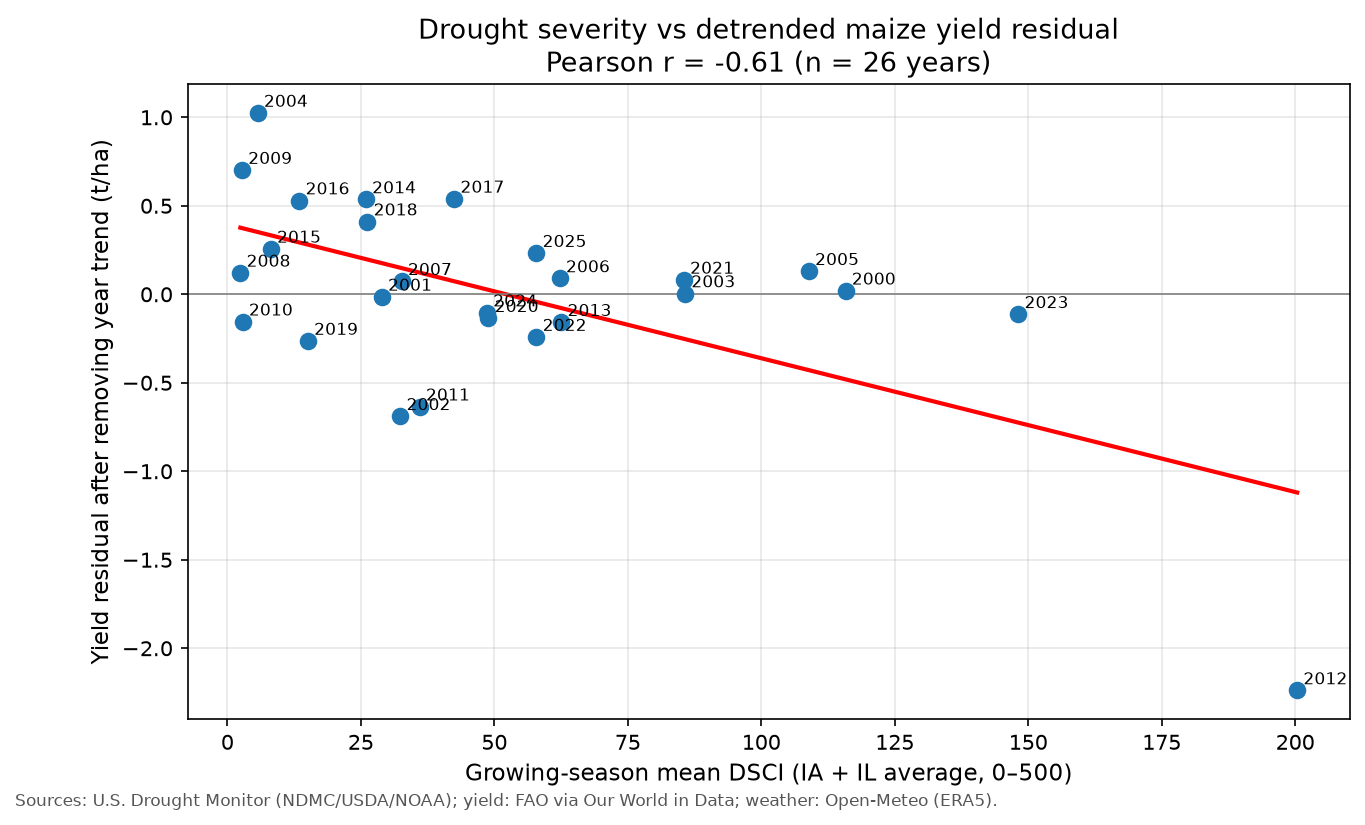

In [5]:
from IPython.display import Image
Image(str(ROOT / "outputs/charts/02_drought_vs_yield.png"))

Growing-season DSCI vs detrended yield: **r = −0.61, p = 0.0009, R² = 0.38** — each extra 100 DSCI points is associated with about 0.76 t/ha less yield (slope −0.0076 t/ha per DSCI point). The precipitation anomaly is weaker and not significant (r = +0.27, p = 0.18), and July rain alone is weaker still (r = +0.24, p = 0.23): the Drought Monitor's blend of rain, temperature, soil moisture and impacts carries more signal than rain totals alone.

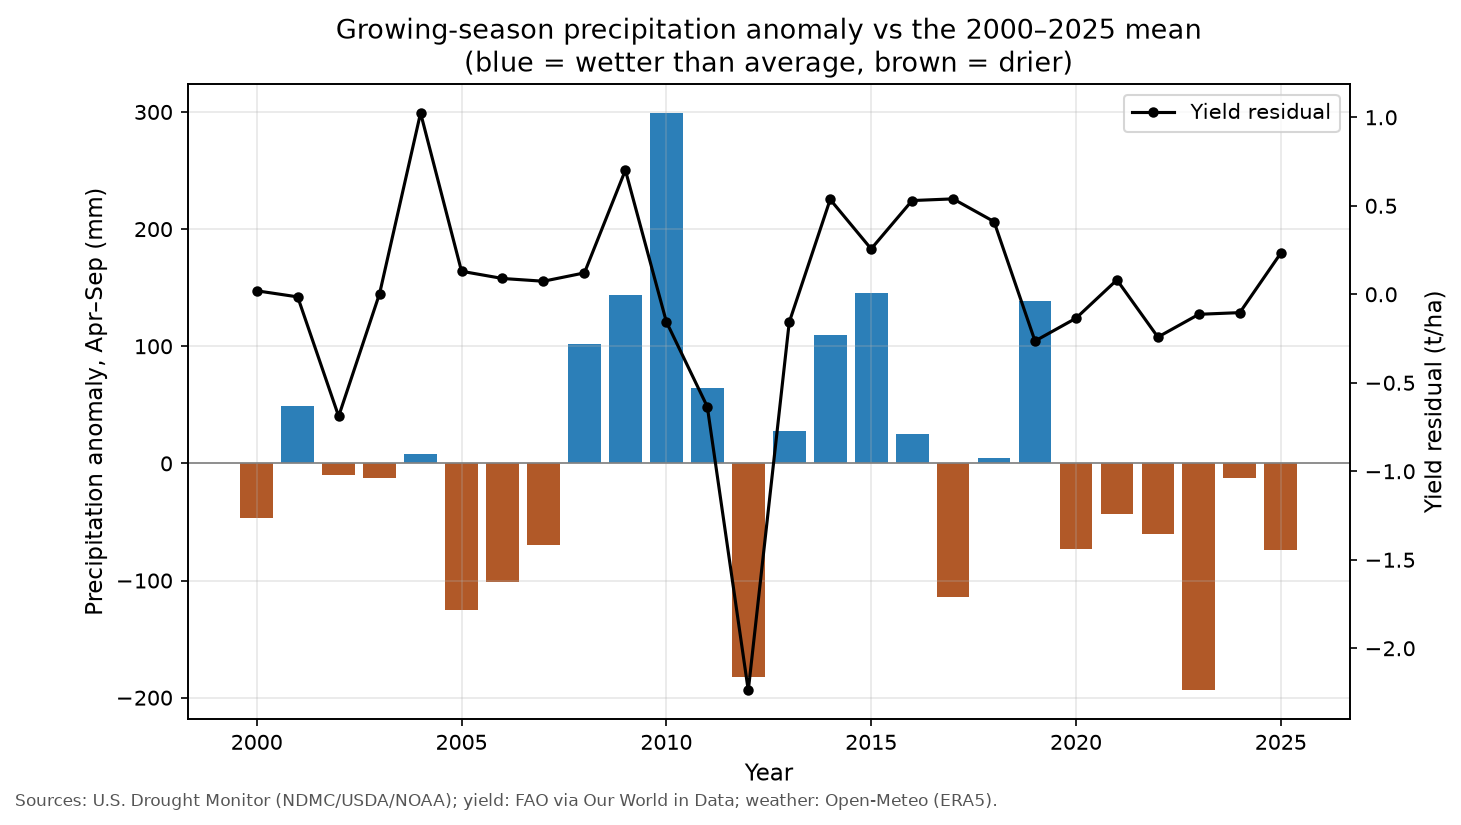

In [6]:
from IPython.display import Image
Image(str(ROOT / "outputs/charts/03_precip_anomaly.png"))

## 4. Counties — Iowa took the worst of it

Top 10 counties by mean % of area in severe-or-worse (D2+) drought over 2000–2025. All ten are in Iowa. The single worst county-year is Woodbury County, IA in 2023: 97.7% of the county in D2+ drought across the growing season.

In [7]:
summary = pd.read_csv(ROOT / "data/processed/county_summary.csv")
summary.head(10).round(2)

,fips,county,state,mean_d2plus_pct,mean_dsci,worst_year,worst_year_d2plus_pct
0,19051,Davis County,IA,12.67,82.85,2023,67.27
1,19021,Buena Vista County,IA,12.60,83.80,2021,78.06
2,19179,Wapello County,IA,12.26,82.78,2023,60.18
3,19193,Woodbury County,IA,11.98,80.55,2023,97.72
4,19177,Van Buren County,IA,11.45,76.75,2023,53.69
5,19133,Monona County,IA,11.07,74.82,2023,88.70
6,19135,Monroe County,IA,10.98,77.46,2023,59.51
7,19025,Calhoun County,IA,10.82,79.86,2012,61.53
8,19007,Appanoose County,IA,10.73,79.25,2023,55.32
9,19161,Sac County,IA,10.53,78.26,2023,62.78


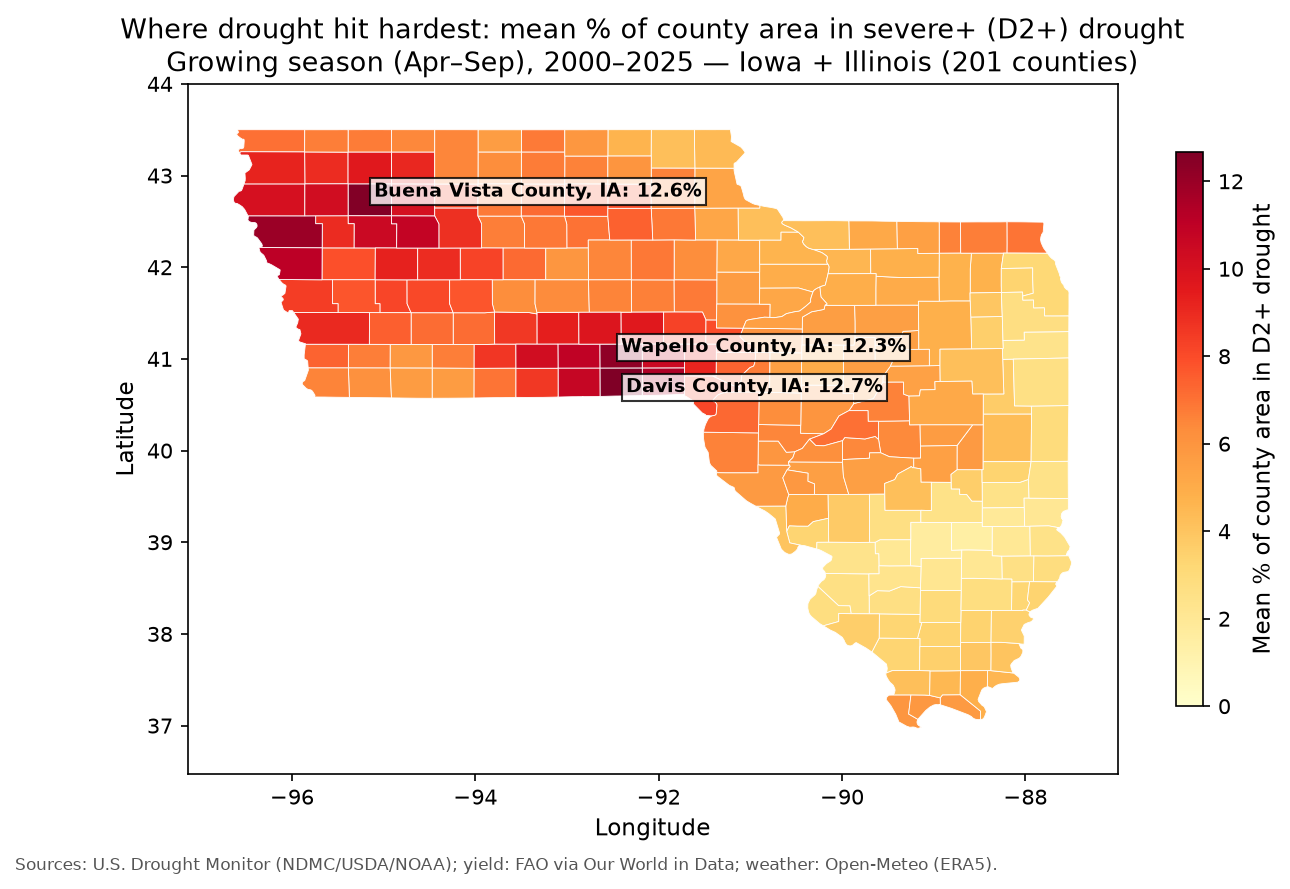

In [8]:
from IPython.display import Image
Image(str(ROOT / "outputs/charts/04_county_map.png"))

## 5. Forecast — AR(1) on annual growing-season DSCI

Backtest: fit on 2000–2024, forecast 2025. The AR(1) beats the naive last-year forecast by a hair (absolute error 8.8 vs 9.3 DSCI points) — drought severity is close to a random walk at annual scale. The 2026 forecast is a statistical extrapolation, not a weather forecast.

In [9]:
forecast = pd.read_csv(ROOT / "data/processed/ar1_forecast.csv")
forecast.round(2)

,year,actual,ar1_forecast,naive_forecast,ar1_abs_error,naive_abs_error,lower,upper
0,2025,57.87,49.03,48.62,8.84,9.25,NaN,NaN
1,2026,NaN,50.16,57.87,NaN,NaN,1.83,98.48


## 6. Conclusions

1. **Drought severity tracks detrended yield closely** (r = −0.61, p = 0.0009): about 38% of the year-to-year yield variation around trend moves with the growing-season DSCI.
2. **Rain totals alone do not explain yield** (r = +0.27, p = 0.18): the USDM blend beats a precipitation anomaly as a yield signal.
3. **2012 is the case study**: DSCI 200.4, rain −183 mm (−31%), yield 2.24 t/ha below trend — the only year the harvest fell that far.
4. **Geography matters**: the worst-hit counties are all in Iowa (Davis County tops the 26-year ranking at 12.7% of area in D2+ drought on average), while southern Illinois is the least exposed.
5. **The 2026 DSCI forecast is 50.2** (interval 1.8–98.5) — a near-average year, but the interval is so wide it is barely more informative than the mean.